In [1]:
import pandas as pd
import joblib
from pathlib import Path
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

from sklearn.utils.class_weight import compute_sample_weight

In [2]:
PROJECT_ROOT = Path.cwd().parent

MODELING_DATA_DIR = PROJECT_ROOT / "data" / "processed" / "modeling"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
MODELS_DIR = PROJECT_ROOT / "models"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
X_train = joblib.load(MODELING_DATA_DIR / "X_train_target_diag.joblib")
X_val = joblib.load(MODELING_DATA_DIR / "X_val_target_diag.joblib")
X_test = joblib.load(MODELING_DATA_DIR / "X_test_target_diag.joblib")

y_train = joblib.load(MODELING_DATA_DIR / "y_train.joblib")
y_val = joblib.load(MODELING_DATA_DIR / "y_val.joblib")
y_test = joblib.load(MODELING_DATA_DIR / "y_test.joblib")

X_train.shape, X_val.shape, X_test.shape

((59604, 168), (19868, 168), (19868, 168))

Proveravamo distribucije ciljne promenljive.

In [4]:
class_distribution = pd.DataFrame({
    "split": ["train", "validation", "test"],
    "rows": [len(y_train), len(y_val), len(y_test)],
    "positive_count": [y_train.sum(), y_val.sum(), y_test.sum()],
    "positive_rate_percent": [
        round(y_train.mean() * 100, 2),
        round(y_val.mean() * 100, 2),
        round(y_test.mean() * 100, 2)
    ]
})

class_distribution

,split,rows,positive_count,positive_rate_percent
0,train,59604,6788,11.39
1,validation,19868,2263,11.39
2,test,19868,2263,11.39


Definisemo tri algoritma za modelovanje. <br>
solver - algoritam za optimizaciju parametara modela lr. <br>
c - jacina regularizacije.<br>
max_iter - maksimalan broj iteracija
class_weight - strategija balansiranja klase.<br>
n_estimators - broj stabala.<br>
max_depth - maksimalna dubina stabla. <br>
min_samples_split - minimalan broj instanci kako bi se stablo granalo. <br>
min_samples_leaf - minimalan broj instanci u cvoru kako bi bio list. <br>
max_features - broj atributa koji se razmatra pri trazenju najboljeg grananja u stablu.<br>
learning rate - stopa ucenja, brzina azuriranja tezina. <br>
subsample - deo trening skupa koji se koristi za izgradnju svakog pojedinacnog stabla.<br>

In [5]:
models = {
    "Logistic Regression": LogisticRegression(
        solver="liblinear",
        C=0.5,
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=50,
        min_samples_leaf=20,
        class_weight="balanced_subsample",
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_samples_split=50,
        min_samples_leaf=20,
        subsample=0.8,
        random_state=42
    )
}

In [6]:
modeling_results = []

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

trained_models = {}

for model_name, model in models.items():
    print(f"Training {model_name}...")

    if model_name == "Gradient Boosting":
        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights
        )
    else:
        model.fit(X_train, y_train)

    y_val_pred = model.predict(X_val)
    y_val_proba = model.predict_proba(X_val)[:, 1]

    modeling_results.append({
        "model": model_name,
        "accuracy": round(accuracy_score(y_val, y_val_pred), 4),
        "precision": round(precision_score(y_val, y_val_pred), 4),
        "recall": round(recall_score(y_val, y_val_pred), 4),
        "f1": round(f1_score(y_val, y_val_pred), 4),
        "roc_auc": round(roc_auc_score(y_val, y_val_proba), 4)
    })

    trained_models[model_name] = model

modeling_results = pd.DataFrame(modeling_results)
modeling_results

Training Logistic Regression...
Training Random Forest...
Training Gradient Boosting...


,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.6626,0.1842,0.5722,0.2787,0.6721
1,Random Forest,0.6839,0.1883,0.5360,0.2787,0.6759
2,Gradient Boosting,0.6482,0.1808,0.5917,0.2770,0.6752


Kao kriterijum za izbor najboljeg modela koristi se f1 score, jer skup podataka sadrzi neuravnotezene klase, a ova metrika istovremeno uzima u obzir preciznost i odziv. <br>
F1 score ce se koristiti i u nastavku rada kako bi poredjenje modela bilo dosledno.

In [7]:
modeling_results_sorted = modeling_results.sort_values(
    by="f1",
    ascending=False
)

modeling_results_sorted

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.6626,0.1842,0.5722,0.2787,0.6721
1,Random Forest,0.6839,0.1883,0.5360,0.2787,0.6759
2,Gradient Boosting,0.6482,0.1808,0.5917,0.2770,0.6752


In [8]:
best_model_name = modeling_results_sorted.iloc[0]["model"]
best_model = trained_models[best_model_name]

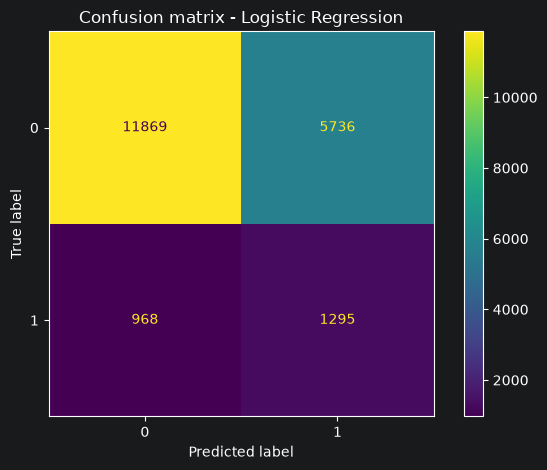

In [9]:
y_val_pred = best_model.predict(X_val)

cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["0", "1"]
)

disp.plot()
plt.title(f"Confusion matrix - {best_model_name}")
plt.tight_layout()
plt.show()

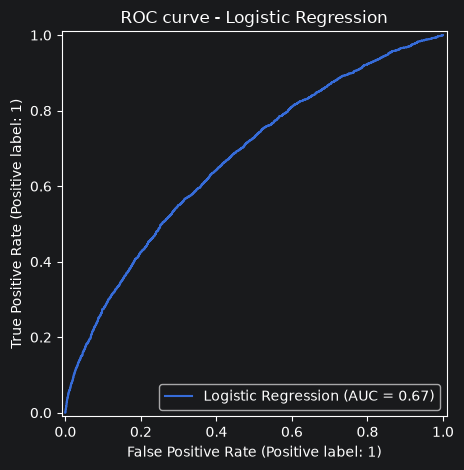

In [10]:
y_val_proba = best_model.predict_proba(X_val)[:, 1]

RocCurveDisplay.from_predictions(
    y_val,
    y_val_proba,
    name=best_model_name
)

plt.title(f"ROC curve - {best_model_name}")
plt.tight_layout()
plt.show()

Cuvamo najbolji model.

In [11]:
joblib.dump(
    best_model,
    MODELS_DIR / f"{best_model_name.lower().replace(' ', '_')}_baseline.pkl"
)

['C:\\Users\\user\\Documents\\MasterRad\\models\\logistic_regression_baseline.pkl']

In [12]:
modeling_results_sorted.to_csv(
    TABLES_DIR / "classical_ml_validation_results.csv",
    index=False
)